## Cellpose-SAM: superhuman generalization for cellular segmentation

Marius Pachitariu, Michael Rariden, Carsen Stringer

[paper](https://www.biorxiv.org/content/10.1101/2025.04.28.651001v1) | [code](https://github.com/MouseLand/cellpose)

This notebook shows how to process your own 2D or 3D images, saved on Google Drive.

This notebook is adapted from the notebook by Pradeep Rajasekhar, inspired by the [ZeroCostDL4Mic notebook series](https://github.com/HenriquesLab/ZeroCostDL4Mic/wiki).

### Make sure you have GPU access enabled by going to Runtime -> Change Runtime Type -> Hardware accelerator and selecting GPU

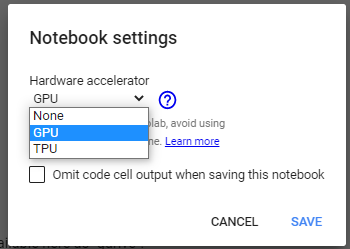

Check GPU and instantiate model - will download weights.

In [1]:
import numpy as np
from cellpose import models, core, io, plot, utils
from pathlib import Path
from tqdm import trange
import matplotlib.pyplot as plt
from natsort import natsorted

io.logger_setup() # run this to get printing of progress

#Check if colab notebook instance has GPU access
if core.use_gpu()==False:
  raise ImportError("No GPU access, change your runtime")

#model = models.CellposeModel(pretrained_model='C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\models\\austen', gpu=True)

model=models.CellposeModel(gpu=True)

### You can also use other pretrained models, like the DINO models 
# model = models.CellposeModel(gpu=True, pretrained_model="cpdino")
# model = models.CellposeModel(gpu=True, pretrained_model="cpdino-vitb")

[GUI INFO] : WRITING LOG OUTPUT TO C:\Users\20223228\.cellpose\run.log

cellpose version: 	4.2.1.1 
platform:       	win32 
python version: 	3.12.14 
torch version:  	2.14.0+cu126
2026-10-11 16:14:14,053 [io INFO] WRITING LOG OUTPUT TO C:\Users\20223228\.cellpose\run.log
2026-10-11 16:14:14,053 [io INFO] 
cellpose version: 	4.2.1.1 
platform:       	win32 
python version: 	3.12.14 
torch version:  	2.14.0+cu126
2026-10-11 16:14:14,330 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-11 16:14:14,330 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-11 16:14:14,330 [core INFO] >>>> using GPU (CUDA)
2026-10-11 16:14:17,357 [models INFO] >>>> loading model C:\Users\20223228\.cellpose\models\cpsam_v2


Input directory with your images:

In [2]:
# *** change to your folder path ***
inputdir = "C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\train\\run_austen\\finetune_parameters"
inputdir = Path(inputdir)
outputdir = "C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\train\\run_austen\\finetune_parameters\\masks"
outputdir = Path(outputdir)

if not inputdir.exists():
  raise FileNotFoundError("directory does not exist")

# *** change to your image extension ***
image_ext = ".tif"

# list all files
files = natsorted([f for f in inputdir.glob("*"+image_ext) if "_masks" not in f.name and "_flows" not in f.name])

if(len(files)==0):
  raise FileNotFoundError("no image files found, did you specify the correct folder and extension?")
else:
  print(f"{len(files)} images in folder:")

for f in files:
  print(f.name)

1 images in folder:
m0_plate2_PointA5_R01_im_Composite_PC_DAPI_Seq0182_Dapi_8bit.tif


## Run Cellpose-SAM on one image in folder

Here are some of the parameters you can change:

* ***flow_threshold*** is  the  maximum  allowed  error  of  the  flows  for  each  mask.   The  default  is 0.4.
    *  **Increase** this threshold if cellpose is not returning as many masks as you’d expect (or turn off completely with 0.0)
    *   **Decrease** this threshold if cellpose is returning too many ill-shaped masks.

* ***cellprob_threshold*** determines proability that a detected object is a cell.   The  default  is 0.0.
    *   **Decrease** this threshold if cellpose is not returning as many masks as you’d expect or if masks are too small
    *   **Increase** this threshold if cellpose is returning too many masks esp from dull/dim areas.

* ***tile_norm_blocksize*** determines the size of blocks used for normalizing the image. The default is 0, which means the entire image is normalized together.
  You may want to change this to 100-200 pixels if you have very inhomogeneous brightness across your image.



In [4]:
img = io.imread(files[0])
#img = img.transpose(1, 2, 0) #added myself to transpose the image to have the channel dimension last, as expected by cellpose
#img = img.astype(np.float32) # Convert to float32

print(f'your image has shape: {img.shape}. Assuming channel dimension is last with {img.shape[-1]} channels')

your image has shape: (2048, 2048, 3). Assuming channel dimension is last with 3 channels


### Channel Selection: 

- Use the dropdowns below to select the _zero-indexed_ channels of your image to segment. The order does not matter. Remember to rerun the cell after you edit the dropdowns.

- If you have a histological image taken in brightfield, you don't need to adjust the channels.

- If you have a fluroescent image with multiple stains, you should choose one channel with a cytoplasm/membrane stain, one channel with a nuclear stain, and set the third channel to `None`. Choosing multiple channels may produce segmentaiton of all the structures in the image. If you have retrained the model on your data with a third stain (described below), you can run segmentation with all channels. 

In [4]:
#Number corresponding to the channel of interest, or 'None' if you want to use all channels.
first_channel = 'None' # @param ['None', 0, 1, 2, 3, 4, 5]
second_channel = 'None' # @param ['None', 0, 1, 2, 3, 4, 5]
third_channel = 'None' # @param ['None', 0, 1, 2, 3, 4, 5]

c:\Users\20223228\.conda\envs\cellposesam\Lib\site-packages\cellpose\dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


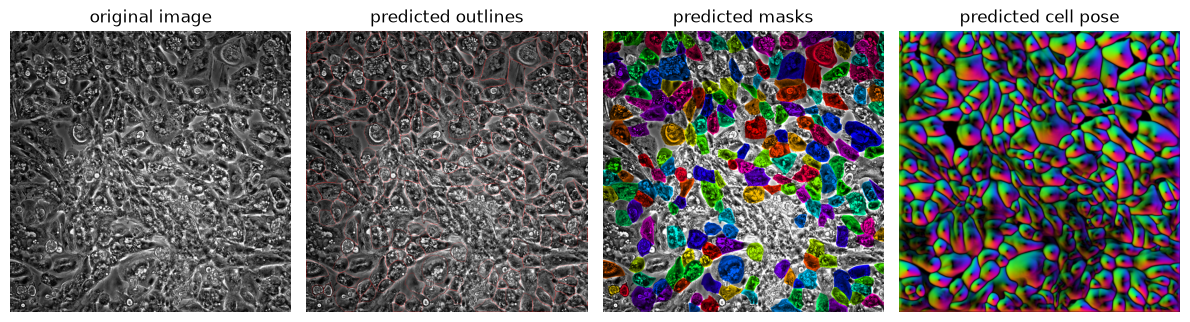

In [5]:
selected_channels = []
for i, c in enumerate([first_channel, second_channel, third_channel]):
  if c == 'None':
    continue
  if int(c) > img.shape[-1]:
    assert False, 'invalid channel index, must have index greater or equal to the number of channels'
  if c != 'None':
    selected_channels.append(int(c))

img_selected_channels = np.zeros_like(img)
if len(selected_channels) == 0:
  img_selected_channels = img
else:
  img_selected_channels[:, :, :len(selected_channels)] = img[:, :, selected_channels]


flow_threshold = 0.4
cellprob_threshold = 0
tile_norm_blocksize = 0

masks, flows, styles = model.eval(img_selected_channels, batch_size=32, flow_threshold=flow_threshold, cellprob_threshold=cellprob_threshold,
                                  normalize={"tile_norm_blocksize": tile_norm_blocksize})

fig = plt.figure(figsize=(12,5))
plot.show_segmentation(fig, img_selected_channels, masks, flows[0])
plt.tight_layout()
plt.show()


## Run Cellpose-SAM on folder of images

if you have many large images, you may want to run them as a loop over images



  0%|          | 0/1 [00:00<?, ?it/s]c:\Users\20223228\.conda\envs\cellposesam\Lib\site-packages\cellpose\dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


m0_plate2_PointA5_R01_im_Composite_PC_DAPI_Seq0182_Dapi_8bit.tif: 1016 masks -> 957 masks (59 masks at the edges removed)


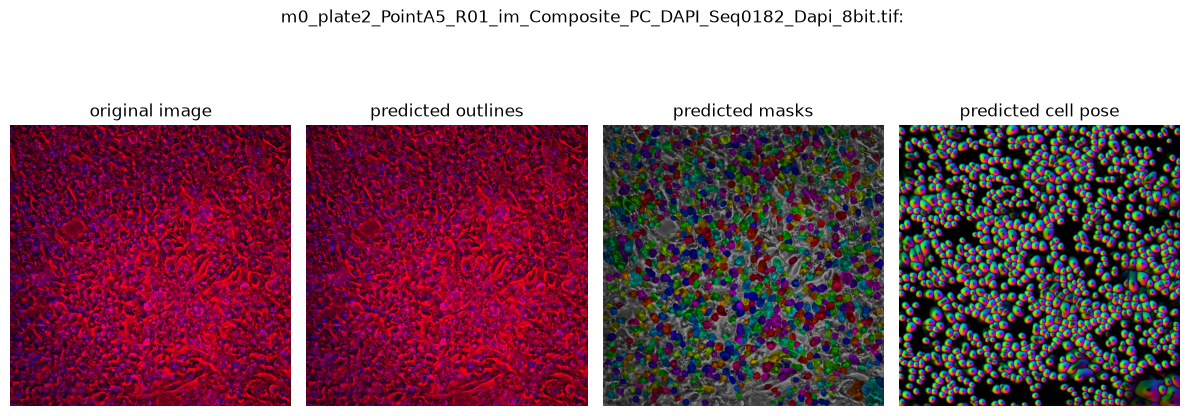

100%|██████████| 1/1 [02:05<00:00, 125.31s/it]

done


In [3]:
masks_ext = ".png" if image_ext == ".png" else ".tif"

flow_threshold = 0.8
cellprob_threshold = 0
tile_norm_blocksize = 0

for i in trange(len(files)):
    f = files[i]
    img = io.imread(f)
    masks, flows, styles = model.eval(img, batch_size=32, flow_threshold=flow_threshold, cellprob_threshold=cellprob_threshold,
                                  normalize={"tile_norm_blocksize": tile_norm_blocksize})

    n_before = len(np.unique(masks)) - 1
    masks = utils.remove_edge_masks(masks)
    n_after = len(np.unique(masks)) - 1

    print(
            f"{f.name}: "
            f"{n_before} masks -> {n_after} masks "
            f"({n_before - n_after} masks at the edges removed)"
    )

    fig = plt.figure(figsize=(12, 5))
    plot.show_segmentation(fig, img, masks, flows[0])
    plt.suptitle(
        f"{f.name}: ")
    plt.tight_layout()
    plt.show()

    
    io.imsave(outputdir / (f.stem + "_masks" + masks_ext), masks)

print("done")

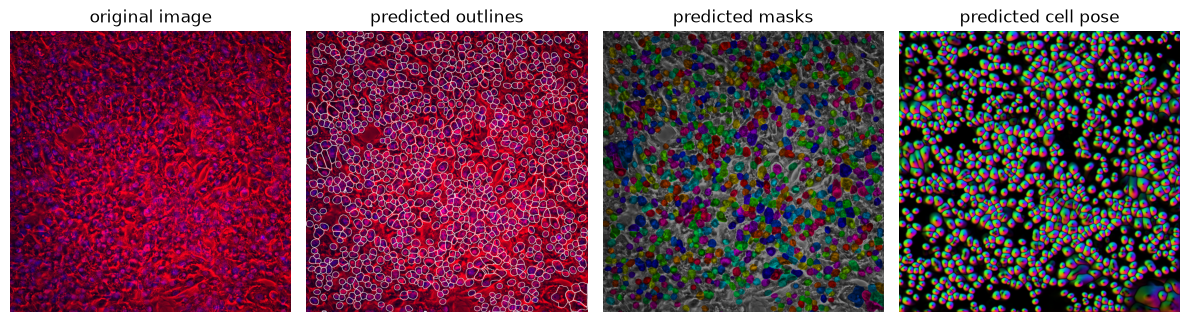

In [ ]:
#shows the segmentation with white outlines instead of red

import numpy as np
import cv2
from cellpose import plot, utils

def show_segmentation_white(fig, img, maski, flowi, channels=[0,0], file_name=None):

    ax = fig.add_subplot(1, 4, 1)
    img0 = img.copy()

    if img0.shape[0] < 4:
        img0 = np.transpose(img0, (1, 2, 0))

    if img0.shape[-1] < 3 or img0.ndim < 3:
        img0 = plot.image_to_rgb(img0, channels=channels)
    else:
        if img0.max() <= 50.0:
            img0 = np.uint8(np.clip(img0, 0, 1) * 255)

    ax.imshow(img0)
    ax.set_title("original image")
    ax.axis("off")

    outlines = utils.masks_to_outlines(maski)

    # make outlines thicker
    kernel = np.ones((3, 3), np.uint8)
    outlines = cv2.dilate(outlines.astype(np.uint8), kernel, iterations=1)

    overlay = plot.mask_overlay(img0, maski)

    ax = fig.add_subplot(1, 4, 2)

    y, x = np.nonzero(outlines)

    imgout = img0.copy()
    imgout[y, x] = [255, 255, 255]  # white outlines

    ax.imshow(imgout)
    ax.set_title("predicted outlines")
    ax.axis("off")

    ax = fig.add_subplot(1, 4, 3)
    ax.imshow(overlay)
    ax.set_title("predicted masks")
    ax.axis("off")

    ax = fig.add_subplot(1, 4, 4)
    ax.imshow(flowi)
    ax.set_title("predicted cell pose")
    ax.axis("off")

# overwrite Cellpose function
plot.show_segmentation = show_segmentation_white

fig = plt.figure(figsize=(12,5))
plot.show_segmentation(fig, img, masks, flows[0])
plt.tight_layout()
plt.show()

if you have small images, you may want to load all of them first and then run, so that they can be batched together on the GPU

In [3]:
masks_ext = ".png" if image_ext == ".png" else ".tif"

flow_threshold = 0.4
cellprob_threshold = 0
tile_norm_blocksize = 0

print("loading images")
imgs = [io.imread(files[i]) for i in trange(len(files))]

print("running cellpose model")
masks, flows, styles = model.eval(imgs, batch_size=32, flow_threshold=flow_threshold, cellprob_threshold=cellprob_threshold,
                                  normalize={"tile_norm_blocksize": tile_norm_blocksize})

for f, mask in zip(files, masks):

    n_before = len(np.unique(mask)) - 1
    io.imsave(outputdir / f"{f.stem}_with_edge_masks{masks_ext}", mask)

    mask_edge_removed = utils.remove_edge_masks(mask)
    n_after = len(np.unique(mask_edge_removed)) - 1

    print(
        f"{f.name}: "
        f"{n_before} masks -> {n_after} masks "
        f"({n_before - n_after} masks at the edges removed)"
    )

    io.imsave(outputdir / f"{f.stem}_without_edge_masks{masks_ext}", mask_edge_removed)


loading images


100%|██████████| 4/4 [00:00<00:00, 33.56it/s]

running cellpose model
2026-10-11 11:40:24,477 [utils INFO] 0%|          | 0/4 [00:00<?, ?it/s]



c:\Users\20223228\.conda\envs\cellposesam\Lib\site-packages\cellpose\dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


2026-10-11 11:46:56,402 [utils INFO] 100%|##########| 4/4 [06:31<00:00, 97.98s/it]
m0_plate1_PointA1_R01_im_Composite_PC_DAPI_Seq0038_Dapi_8bit.tif: 389 masks -> 388 masks (1 masks at the edges removed)
m0_plate2_PointA5_R01_im_Composite_PC_DAPI_Seq0182_Dapi_8bit.tif: 346 masks -> 345 masks (1 masks at the edges removed)
m1_plate1_PointA2_R01_im_Composite_PC_DAPI_Seq0074_Dapi_8bit.tif: 301 masks -> 300 masks (1 masks at the edges removed)
m1_plate2_PointA1_R01_im_Composite_PC_DAPI_Seq0038_Dapi_8bit.tif: 312 masks -> 306 masks (6 masks at the edges removed)


ValueError: masks_to_outlines takes 2D or 3D array, not 1D array

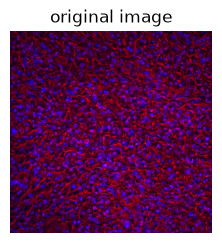

In [8]:
#Visualization of the segmentation results

for f, img, mask, flow in zip(files, imgs, masks, flows):

    n_before = len(np.unique(mask)) - 1
    mask_edge_removed = utils.remove_edge_masks(mask)
    n_after = len(np.unique(mask_edge_removed)) - 1

    fig = plt.figure(figsize=(12, 5))

    plot.show_segmentation(fig, img, mask, mask_edge_removed, flow)

    plt.suptitle(
        f"{f.name}: "
        f"{f.name}: {n_before} masks → {n_after} masks "
        f"({n_before - n_after} masks at the edges removed)"
    )

    plt.tight_layout()
    plt.show()